# Experiment C — Individual preprocessing techniques

Compare baseline, grayscale, non-local means denoising, deskewing, and CLAHE using one pretrained TrOCR checkpoint and identical IAM validation lines. No training is performed. This is the individual-technique experiment called Experiment A in the current research plan; we use the requested name Experiment C here.

The initial run uses 100 seeded validation lines. Set SAMPLE_COUNT to None for the full validation split. These are development results, not a final test evaluation. Parameters are starting settings, not validated optimal choices. Keep test data reserved.

Scoring collapses whitespace and retains case and punctuation. Corpus CER/WER aggregate edit counts, not mean line rates. Rates can exceed 100%. IAM transcription conventions (including punctuation spacing) contribute to error. TrOCR's mandatory RGB conversion, resize, and normalization run identically after each optional treatment.

In [1]:
from pathlib import Path
import sys
import json
import platform
from datetime import datetime, timezone
from importlib.metadata import version

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "src/load_dataset/iam.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.load_dataset.iam import load_iam_dataset, get_sample
from src.models import TrOCRRecognizer
from src.preprocessing import (PreprocessingPipeline, Grayscale, NonLocalMeans, Deskew, CLAHE)
from src.evaluation import compare_recognition

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
SPLIT = "validation"
DATASET_REVISION = "fbdad97500ce54635c0d1ba306bf535cb40656cf"
CHECKPOINT = "microsoft/trocr-base-handwritten"
MODEL_REVISION = "eaacaf452b06415df8f10bb6fad3a4c11e609406"
DEVICE = "cpu"
SAMPLE_COUNT = 100  # None evaluates the complete validation split.
SEED = 5112
GENERATION = {"max_new_tokens": 128, "num_beams": 1, "do_sample": False}
pipelines = {
    "baseline": PreprocessingPipeline(),
    "grayscale": PreprocessingPipeline((Grayscale(),)),
    "denoising": PreprocessingPipeline((NonLocalMeans(h=3.0, h_color=3.0),)),
    "deskew": PreprocessingPipeline((Deskew(max_angle=10.0, angle_step=0.5),)),
    "clahe": PreprocessingPipeline((CLAHE(clip_limit=2.0, tile_grid_size=(8, 8)),)),
}
assert SPLIT == "validation", "This notebook is for development; keep test data reserved."
print(json.dumps({name: pipe.to_config() for name, pipe in pipelines.items()}, indent=2))

{
  "baseline": {
    "steps": []
  },
  "grayscale": {
    "steps": [
      {
        "name": "grayscale",
        "enabled": true,
        "output_mode": "L"
      }
    ]
  },
  "denoising": {
    "steps": [
      {
        "name": "non_local_means",
        "enabled": true,
        "h": 3.0,
        "h_color": 3.0,
        "template_window_size": 7,
        "search_window_size": 21
      }
    ]
  },
  "deskew": {
    "steps": [
      {
        "name": "deskew",
        "enabled": true,
        "max_angle": 10.0,
        "angle_step": 0.5,
        "estimator": "otsu_projection_difference",
        "resampling": "bicubic",
        "expand": true,
        "fill": "white"
      }
    ]
  },
  "clahe": {
    "steps": [
      {
        "name": "clahe",
        "enabled": true,
        "clip_limit": 2.0,
        "tile_grid_size": [
          8,
          8
        ],
        "processing": "grayscale directly; RGB via LAB luminance"
      }
    ]
  }
}


In [3]:
dataset = load_iam_dataset(split=SPLIT, revision=DATASET_REVISION)
assert {"image", "text"}.issubset(dataset.column_names)
if SAMPLE_COUNT is None:
    indices = list(range(len(dataset)))
else:
    assert type(SAMPLE_COUNT) is int and 0 < SAMPLE_COUNT <= len(dataset)
    indices = sorted(np.random.default_rng(SEED).choice(len(dataset), SAMPLE_COUNT, replace=False).tolist())
samples = [get_sample(dataset, i) for i in indices]
assert len({s["id"] for s in samples}) == len(samples)
assert all(isinstance(s["ground_truth"], str) and s["ground_truth"].strip() for s in samples)
assert all(s["image"].mode in ("L", "RGB") for s in samples)
sample_info = pd.DataFrame([{
    "sample_id": s["id"], "dataset_index": i, "mode": s["image"].mode,
    "width": s["image"].width, "height": s["image"].height,
    "reference_characters": len(s["ground_truth"]), "ground_truth": s["ground_truth"],
} for i, s in zip(indices, samples)])
print(f"IAM {SPLIT}: {len(dataset)} available; {len(samples)} selected; revision {DATASET_REVISION}")
display(sample_info.head())
display(sample_info["mode"].value_counts().rename("selected_images").to_frame())
grayscale_is_identity = all(s["image"].mode == "L" for s in samples)
print("Grayscale is pixel-identical to baseline on this selected set:", grayscale_is_identity)

Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields


IAM validation: 976 available; 100 selected; revision fbdad97500ce54635c0d1ba306bf535cb40656cf


,sample_id,dataset_index,mode,width,height,reference_characters,ground_truth
0,sample_3,3,L,1355,128,43,with James Maxwell making a fine job of the
1,sample_43,43,L,2250,128,43,"15,695 times in their different grammatical"
2,sample_48,48,L,2187,128,37,large . But the British text includes
3,sample_54,54,L,2305,128,39,"the difference between the 15,695 words"
4,sample_58,58,L,2135,128,33,in Neh. 2.8 and S. of Sol. 4.13 .


,selected_images
mode,
L,100


Grayscale is pixel-identical to baseline on this selected set: True


## Recognition and saved artifacts

Load the model once and run a warm-up outside recorded timings. Each treatment processes every selected line in the same order. Timing includes mandatory processor transforms and generation, excludes model loading, and records optional preprocessing separately. CPU timings are descriptive; this single sequential run is not a controlled speed benchmark.

A fresh results directory is written immediately after inference, before plotting. It contains raw predictions and references, corpus summaries, selected sample information, and reproducibility metadata. No existing results are overwritten.

In [4]:
model = TrOCRRecognizer(checkpoint=CHECKPOINT, revision=MODEL_REVISION,
                         device=DEVICE, generation_kwargs=GENERATION)
_ = model.predict(samples[0]["image"])  # Unscored warm-up.
rows, summaries = compare_recognition(samples, model, pipelines)
predictions = pd.DataFrame(rows)
summary = pd.DataFrame(summaries).set_index("configuration").loc[list(pipelines)]
assert (summary["scored_sample_count"] == len(samples)).all()
for name in pipelines:
    ids = predictions.loc[predictions["configuration"] == name, "sample_id"].tolist()
    assert ids == [s["id"] for s in samples]
for metric in ("cer", "wer"):
    baseline_value = summary.loc["baseline", metric]
    summary[f"{metric}_change_pp"] = 100 * (summary[metric] - baseline_value)
    summary[f"{metric}_relative_change_pct"] = (
        100 * (summary[metric] - baseline_value) / baseline_value if baseline_value else np.nan
    )
summary["preprocessing_seconds"] = predictions.groupby("configuration")["preprocessing_seconds"].sum()
summary["total_seconds"] = summary["preprocessing_seconds"] + summary["inference_seconds"]
summary["seconds_per_line"] = summary["total_seconds"] / summary["sample_count"]
if grayscale_is_identity:
    baseline_predictions = predictions.query("configuration == 'baseline'")["prediction"].tolist()
    assert predictions.query("configuration == 'grayscale'")["prediction"].tolist() == baseline_predictions

run_id = "experiment_c_" + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
run_dir = ROOT / "results" / run_id
run_dir.mkdir(parents=True, exist_ok=False)
metadata = {
    "experiment_id": run_id, "created_utc": datetime.now(timezone.utc).isoformat(),
    "experiment": "Individual preprocessing techniques; TrOCR; IAM validation",
    "dataset": "Teklia/IAM-line", "split": SPLIT, "dataset_revision": DATASET_REVISION,
    "dataset_fingerprint": dataset._fingerprint, "split_size": len(dataset),
    "sample_indices": indices, "sample_count": len(samples), "seed": SEED,
    "sampling": "all rows if SAMPLE_COUNT is None; otherwise seeded sampling without replacement, sorted indices",
    "model": model.to_config(),
    "preprocessing": {name: pipe.to_config() for name, pipe in pipelines.items()},
    "normalization": "collapse whitespace; strip edges; retain case and punctuation",
    "grayscale_is_identity": grayscale_is_identity,
    "timing": "wall seconds; warm-up excluded; model loading excluded; mandatory transforms included in inference",
    "python": platform.python_version(), "platform": platform.platform(),
    "versions": {p: version(p) for p in ("torch", "transformers", "datasets", "huggingface-hub",
        "jiwer", "numpy", "Pillow", "opencv-python-headless", "pandas", "matplotlib")},
}
predictions.to_csv(run_dir / "predictions.csv", index=False)
summary.to_csv(run_dir / "summary.csv")
sample_info.to_csv(run_dir / "samples.csv", index=False)
(run_dir / "metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
display(summary)
print("Saved:", run_dir)

W1108 18:52:24.150000 9149 .venv/lib/python3.13/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/478 [00:00<?, ?it/s]

[transformers] VisionEncoderDecoderModel LOAD REPORT from: microsoft/trocr-base-handwritten
Key                         | Status  | 
----------------------------+---------+-
encoder.pooler.dense.weight | MISSING | 
encoder.pooler.dense.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


baseline: 1/100
baseline: 2/100
baseline: 3/100
baseline: 4/100
baseline: 5/100
baseline: 6/100
baseline: 7/100
baseline: 8/100
baseline: 9/100
baseline: 10/100
baseline: 11/100
baseline: 12/100
baseline: 13/100
baseline: 14/100
baseline: 15/100
baseline: 16/100
baseline: 17/100
baseline: 18/100
baseline: 19/100
baseline: 20/100
baseline: 21/100
baseline: 22/100
baseline: 23/100
baseline: 24/100
baseline: 25/100
baseline: 26/100
baseline: 27/100
baseline: 28/100
baseline: 29/100
baseline: 30/100
baseline: 31/100
baseline: 32/100
baseline: 33/100
baseline: 34/100
baseline: 35/100
baseline: 36/100
baseline: 37/100
baseline: 38/100
baseline: 39/100
baseline: 40/100
baseline: 41/100
baseline: 42/100
baseline: 43/100
baseline: 44/100
baseline: 45/100
baseline: 46/100
baseline: 47/100
baseline: 48/100
baseline: 49/100
baseline: 50/100
baseline: 51/100
baseline: 52/100
baseline: 53/100
baseline: 54/100
baseline: 55/100
baseline: 56/100
baseline: 57/100
baseline: 58/100
baseline: 59/100
baseli

,sample_count,scored_sample_count,cer,wer,inference_seconds,cer_change_pp,cer_relative_change_pct,wer_change_pp,wer_relative_change_pct,preprocessing_seconds,total_seconds,seconds_per_line
configuration,,,,,,,,,,,,
baseline,100,100,0.007770,0.026077,83.223065,0.000000,0.000000,0.000000,0.000000,0.006081,83.229146,0.832291
grayscale,100,100,0.007770,0.026077,83.196810,0.000000,0.000000,0.000000,0.000000,0.008563,83.205374,0.832054
denoising,100,100,0.009183,0.029478,83.475783,0.141276,18.181818,0.340136,13.043478,5.482771,88.958554,0.889586
deskew,100,100,0.006122,0.023810,83.077785,-0.164822,-21.212121,-0.226757,-8.695652,3.330532,86.408317,0.864083
clahe,100,100,0.011538,0.029478,81.392028,0.376737,48.484848,0.340136,13.043478,0.045936,81.437964,0.814380


Saved: /Users/vmendoza/Documents/Lakehead/RM/COMP-5112-Research-Methodology/results/experiment_c_20261108T235931207473Z


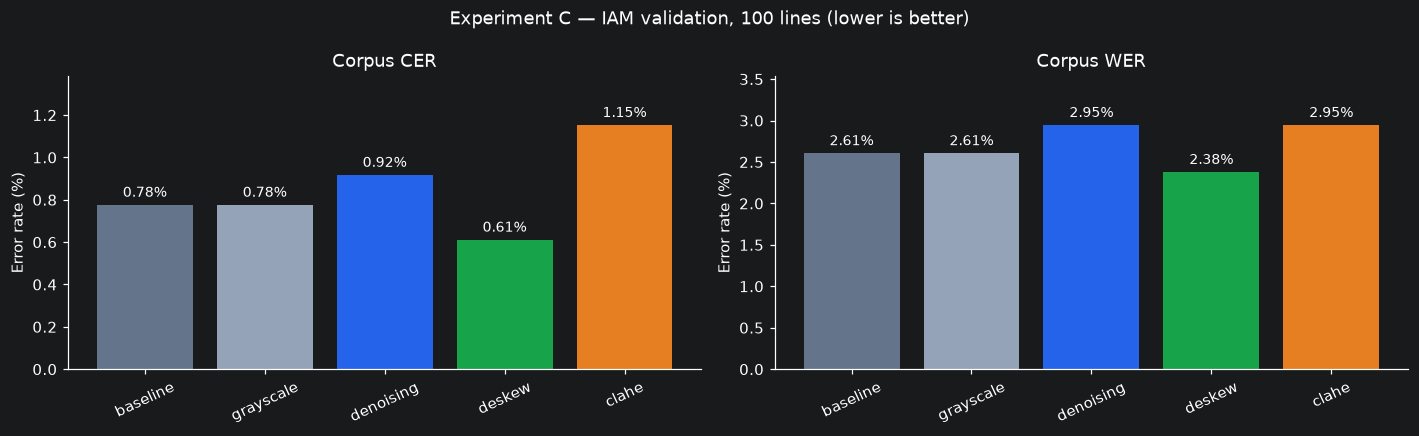

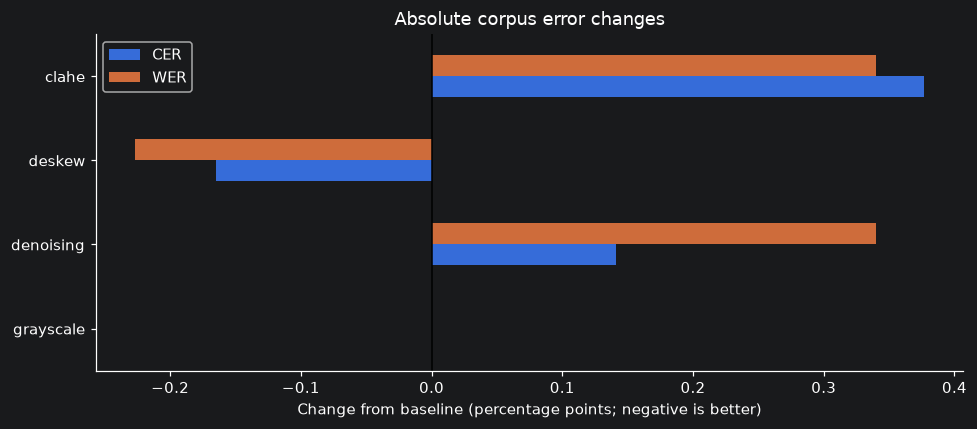

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metric in zip(axes, ("cer", "wer")):
    values = 100 * summary[metric]
    bars = ax.bar(summary.index, values, color=["#64748b", "#94a3b8", "#2563eb", "#16a34a", "#e67e22"])
    ax.bar_label(bars, labels=[f"{v:.2f}%" for v in values], padding=3, fontsize=9)
    ax.set(title=f"Corpus {metric.upper()}", ylabel="Error rate (%)")
    ax.tick_params(axis="x", rotation=25)
    ax.margins(y=0.2)
fig.suptitle(f"Experiment C — IAM validation, {len(samples)} lines (lower is better)")
fig.tight_layout()
fig.savefig(run_dir / "corpus_error_rates.png", bbox_inches="tight")
plt.show()

changes = summary.drop(index="baseline")[["cer_change_pp", "wer_change_pp"]]
ax = changes.rename(columns={"cer_change_pp": "CER", "wer_change_pp": "WER"}).plot.barh(figsize=(9, 4))
ax.axvline(0, color="black", linewidth=1)
ax.set(xlabel="Change from baseline (percentage points; negative is better)",
       ylabel="", title="Absolute corpus error changes")
plt.tight_layout()
plt.savefig(run_dir / "corpus_changes.png", bbox_inches="tight")
plt.show()

## Where does preprocessing help or hurt?

The next plots pair each line with its own baseline. The scatter diagonal means equal CER. The count chart uses per-line CER to count improved, unchanged, and worsened lines; these counts are diagnostics, not corpus metrics or a statistical significance test. A technique can help many short lines and still worsen corpus CER if it damages longer lines.

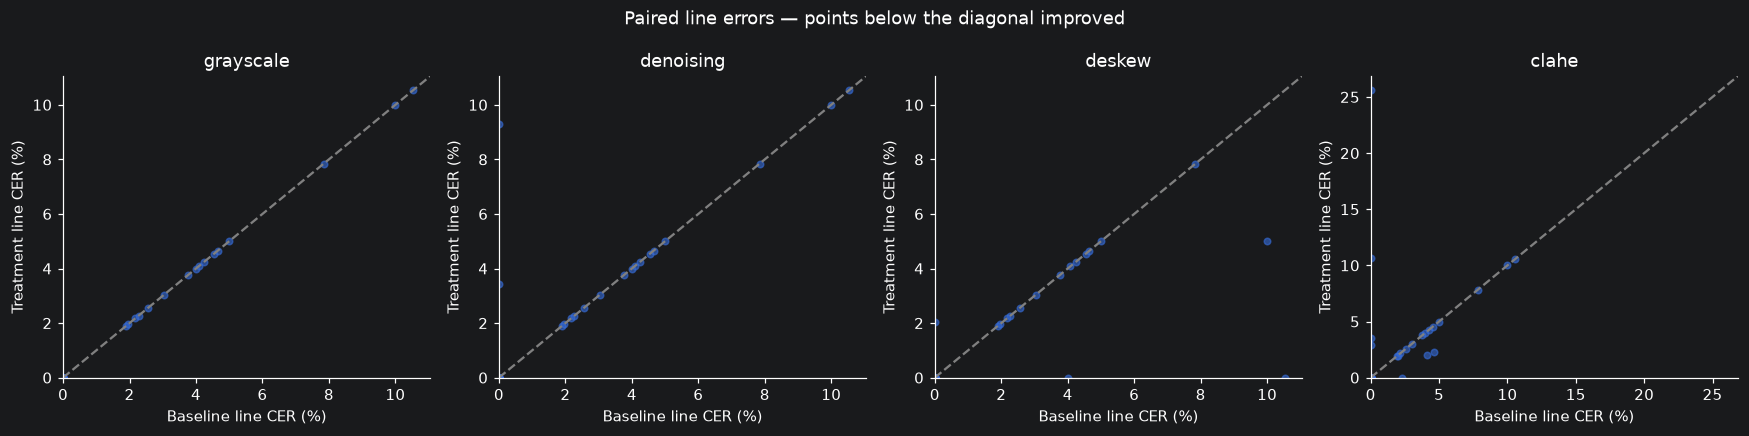

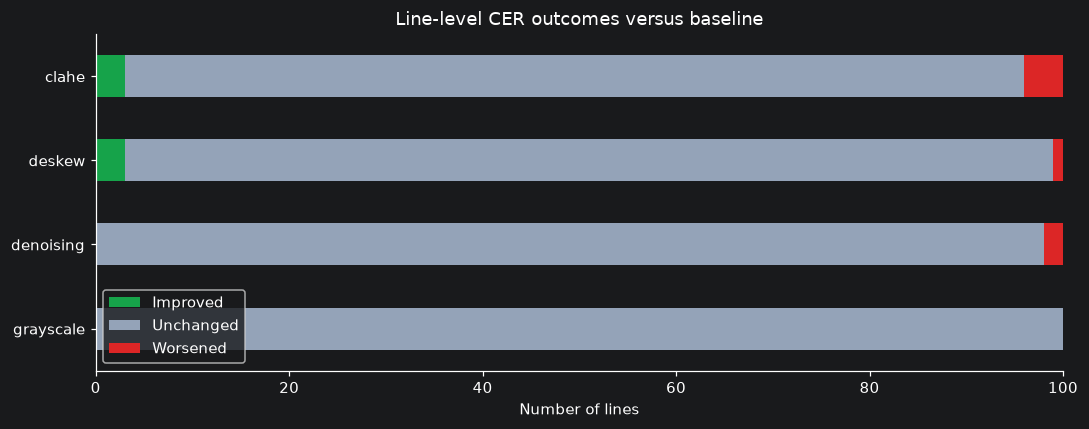

,Improved,Unchanged,Worsened
grayscale,0,100,0
denoising,0,98,2
deskew,3,96,1
clahe,3,93,4


In [6]:
paired = predictions.pivot(index="sample_id", columns="configuration", values="cer")
treatments = [name for name in pipelines if name != "baseline"]
fig, axes = plt.subplots(1, len(treatments), figsize=(16, 4), squeeze=False)
outcomes = {}
for ax, name in zip(axes[0], treatments):
    x, y = 100 * paired["baseline"], 100 * paired[name]
    limit = max(float(x.max()), float(y.max()), 1) * 1.05
    ax.scatter(x, y, alpha=0.6, s=18)
    ax.plot([0, limit], [0, limit], "--", color="gray")
    ax.set(xlim=(0, limit), ylim=(0, limit), xlabel="Baseline line CER (%)",
           ylabel="Treatment line CER (%)", title=name)
    delta = paired[name] - paired["baseline"]
    same = np.isclose(delta, 0, atol=1e-12, rtol=0)
    outcomes[name] = {"Improved": int(((delta < 0) & ~same).sum()),
                      "Unchanged": int(same.sum()),
                      "Worsened": int(((delta > 0) & ~same).sum())}
fig.suptitle("Paired line errors — points below the diagonal improved")
fig.tight_layout()
fig.savefig(run_dir / "paired_line_cer.png", bbox_inches="tight")
plt.show()
outcomes = pd.DataFrame.from_dict(outcomes, orient="index")
ax = outcomes.plot.barh(stacked=True, color=["#16a34a", "#94a3b8", "#dc2626"], figsize=(10, 4))
ax.set(xlabel="Number of lines", ylabel="", title="Line-level CER outcomes versus baseline")
plt.tight_layout()
plt.savefig(run_dir / "line_outcomes.png", bbox_inches="tight")
plt.show()
outcomes.to_csv(run_dir / "line_outcomes.csv")
display(outcomes)

grayscale: no line-level CER changes; showing the first selected line.

grayscale | sample_3 | CER change +0.00 pp
Reference: with James Maxwell making a fine job of the
Baseline:  with James Maxwell making a fine job of the
Treatment: with James Maxwell making a fine job of the


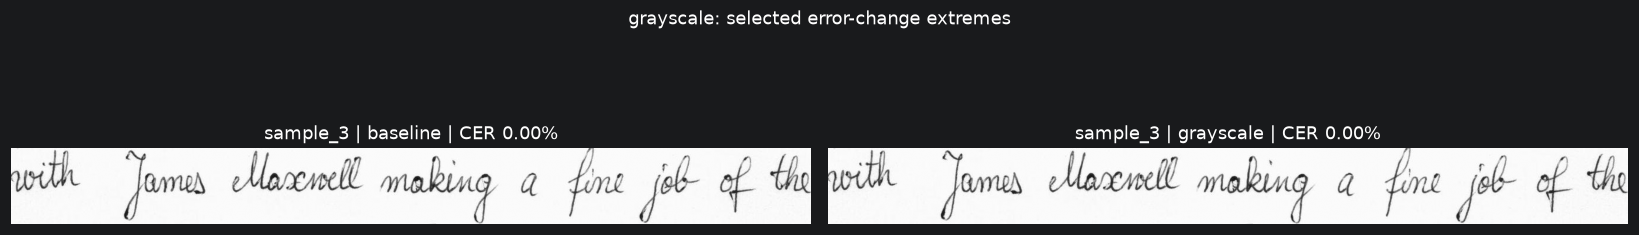


denoising | sample_140 | CER change +0.00 pp
Reference: from innocence .
Baseline:  from innocence .
Treatment: from innocence .

denoising | sample_43 | CER change +9.30 pp
Reference: 15,695 times in their different grammatical
Baseline:  15,695 times in their different grammatical
Treatment: " S.695 times in their different grammatical


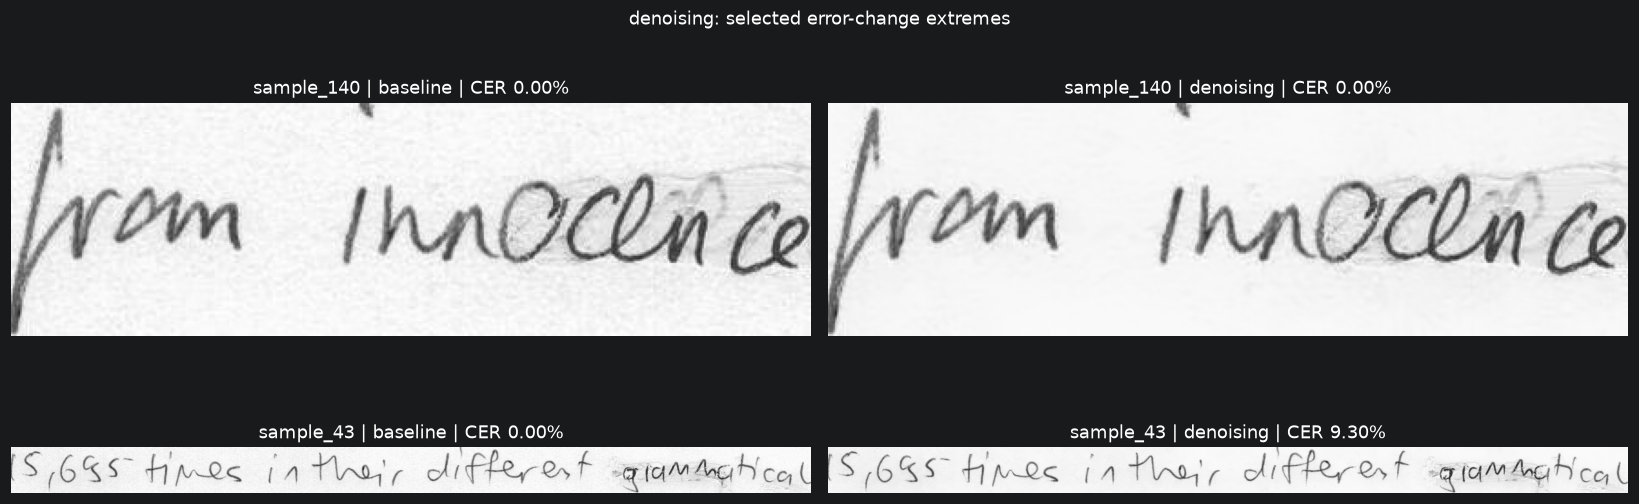


deskew | sample_480 | CER change -10.53 pp
Reference: resemblance to the shrunk heads we had
Baseline:  resentplace to the shrunk heads we had
Treatment: resemblance to the shrunk heads we had

deskew | sample_556 | CER change +2.04 pp
Reference: back in his chair . " I see . So you met a bus at
Baseline:  back in his chair . " I see . So you met a bus at
Treatment: back in his chain . " I see . So you met a bus at


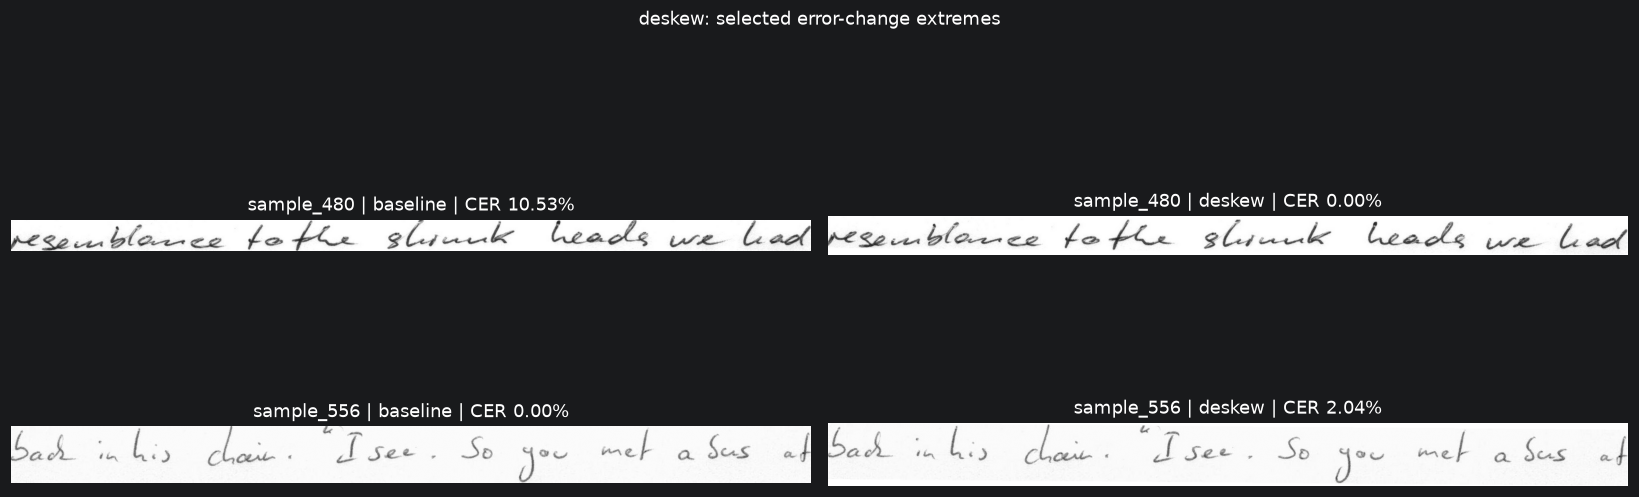


clahe | sample_757 | CER change -2.33 pp
Reference: 'Light an' come on in . " We dismounted and
Baseline:  ' light an' come on in . " We dismounted and
Treatment: Light an' come on in . " We dismounted and

clahe | sample_43 | CER change +25.58 pp
Reference: 15,695 times in their different grammatical
Baseline:  15,695 times in their different grammatical
Treatment: " S.695 times in their different educational


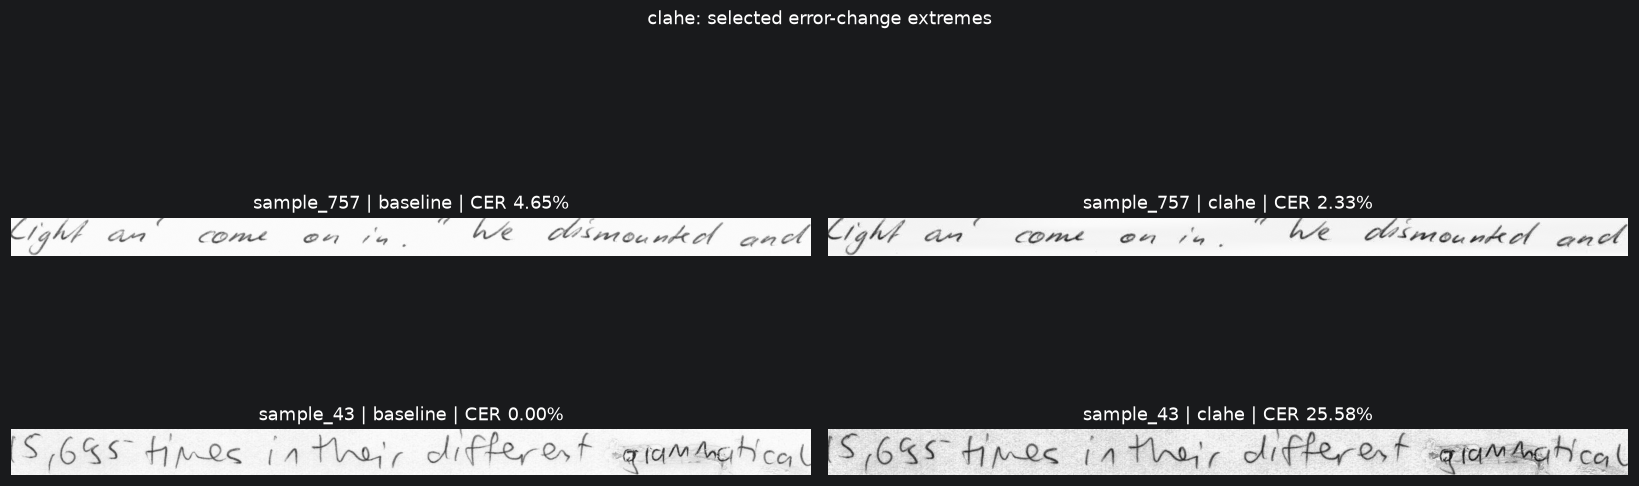

In [7]:
# Show each treatment's largest improvement and largest regression.
# These are deliberately selected extremes, not representative examples.
sample_by_id = {s["id"]: s for s in samples}
prediction_lookup = predictions.set_index(["sample_id", "configuration"])
for name in treatments:
    delta = paired[name] - paired["baseline"]
    if np.allclose(delta, 0, atol=1e-12, rtol=0):
        print(f"{name}: no line-level CER changes; showing the first selected line.")
        example_ids = [samples[0]["id"]]
    else:
        example_ids = list(dict.fromkeys([delta.idxmin(), delta.idxmax()]))
    fig, axes = plt.subplots(len(example_ids), 2, figsize=(15, 3 * len(example_ids)), squeeze=False)
    for row, sample_id in enumerate(example_ids):
        sample = sample_by_id[sample_id]
        for col, config in enumerate(("baseline", name)):
            image = pipelines[config](sample["image"])
            axes[row, col].imshow(image, cmap="gray", vmin=0, vmax=255)
            axes[row, col].set_title(f"{sample_id} | {config} | CER {100 * paired.loc[sample_id, config]:.2f}%")
            axes[row, col].axis("off")
        print(f"\n{name} | {sample_id} | CER change {100 * delta.loc[sample_id]:+.2f} pp")
        print("Reference:", sample["ground_truth"])
        print("Baseline: ", prediction_lookup.loc[(sample_id, "baseline"), "prediction"])
        print("Treatment:", prediction_lookup.loc[(sample_id, name), "prediction"])
    fig.suptitle(f"{name}: selected error-change extremes")
    fig.tight_layout()
    fig.savefig(run_dir / f"examples_{name}.png", bbox_inches="tight")
    plt.show()

## Interpretation and next steps

Use corpus CER/WER as the primary outcomes and paired examples to investigate possible causes. A negative change means lower error; a relative change is undefined when baseline error is zero. Grayscale on already-L images is a redundancy check, not an independent enhancement. Deskewing can change canvas dimensions and therefore scaling during the mandatory model resize.

These validation observations do not establish statistical significance or generalization to unseen test data, other models, or languages. Use them for development, document any parameter changes, and repeat the fixed configurations on the full validation split before selecting combinations. Keep final test evaluation separate. Saved timings describe this machine and run, not model-independent speed gains.